# Feature Engineering

### Loding data and Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_csv("../Data/cleaned_exoplanet_data.csv")

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (38624, 28)


,sy_snum,sy_pnum,st_teff,st_tefflim,st_rad,st_radlim,st_logglim,ra,dec,sy_dist,...,sy_gaiamag,sy_gaiamagerr1,sy_gaiamagerr2,sy_name,hostname,tic_id,st_refname,sy_refname,rastr,decstr
0,2.0,1.0,4742.000,0.0,19.000,0.0,0.0,185.178779,17.793252,93.1846,...,4.44038,0.003848,-0.003848,11 Com,11 Com,TIC 72437047,<a refstr=LIU_ET_AL__2008 href=https://ui.adsa...,<a refstr=STASSUN_ET_AL__2019 href=https://ui....,12h20m42.91s,+17d47m35.71s
1,2.0,1.0,4741.436,0.0,16.626,0.0,0.0,185.178779,17.793252,93.1846,...,4.44038,0.003848,-0.003848,11 Com,11 Com,TIC 72437047,<a refstr=KUNITOMO_ET_AL__2011 href=https://ui...,<a refstr=STASSUN_ET_AL__2019 href=https://ui....,12h20m42.91s,+17d47m35.71s
2,2.0,1.0,4830.000,0.0,3.990,0.0,0.0,185.178779,17.793252,93.1846,...,4.44038,0.003848,-0.003848,11 Com,11 Com,TIC 72437047,<a refstr=MORTIER_ET_AL__2013 href=https://ui....,<a refstr=STASSUN_ET_AL__2019 href=https://ui....,12h20m42.91s,+17d47m35.71s
3,2.0,1.0,4705.000,0.0,15.780,0.0,0.0,185.178779,17.793252,93.1846,...,4.44038,0.003848,-0.003848,11 Com,11 Com,TIC 72437047,<a refstr=VON_BRAUN_ET_AL__2014 href=https://u...,<a refstr=STASSUN_ET_AL__2019 href=https://ui....,12h20m42.91s,+17d47m35.71s
4,2.0,1.0,4741.436,0.0,16.626,0.0,0.0,185.178779,17.793252,93.1846,...,4.44038,0.003848,-0.003848,11 Com,11 Com,TIC 72437047,<a refstr=CANNON___PICKERING_1918 href=https:/...,<a refstr=STASSUN_ET_AL__2019 href=https://ui....,12h20m42.91s,+17d47m35.71s


In [3]:
print("Duplicates before:", df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicates after:", df.duplicated().sum())

print("New shape:", df.shape)

Duplicates before: 43
Duplicates after: 0
New shape: (38581, 28)


In [4]:
# V magnitude - K magnitude
df["color_v_k"] = df["sy_vmag"] - df["sy_kmag"]

# Gaia magnitude - V magnitude
df["color_gaia_v"] = df["sy_gaiamag"] - df["sy_vmag"]

# Gaia magnitude - K magnitude
df["color_gaia_k"] = df["sy_gaiamag"] - df["sy_kmag"]

In [5]:
# Avoid invalid logarithms
distance = df["sy_dist"].where(df["sy_dist"] > 0)

# Distance modulus
df["distance_modulus"] = 5 * np.log10(distance) - 5

# Absolute magnitudes
df["absolute_v_mag"] = df["sy_vmag"] - df["distance_modulus"]

df["absolute_k_mag"] = df["sy_kmag"] - df["distance_modulus"]

df["absolute_gaia_mag"] = df["sy_gaiamag"] - df["distance_modulus"]

In [6]:
# Stellar luminosity relative to the Sun

df["stellar_luminosity"] = (
    df["st_rad"] ** 2 *
    (df["st_teff"] / 5772) ** 4
)

# Log transformation
df["log_stellar_luminosity"] = np.log10(
    df["stellar_luminosity"].where(df["stellar_luminosity"] > 0)
)

In [7]:
df["log_st_teff"] = np.log10(
    df["st_teff"].where(df["st_teff"] > 0)
)

df["log_st_rad"] = np.log10(
    df["st_rad"].where(df["st_rad"] > 0)
)

df["log_sy_dist"] = np.log10(
    df["sy_dist"].where(df["sy_dist"] > 0)
)

In [8]:
# Average absolute uncertainty for V magnitude
df["v_mag_error_mean"] = (
    df["sy_vmagerr1"].abs() +
    df["sy_vmagerr2"].abs()
) / 2

# Average absolute uncertainty for K magnitude
df["k_mag_error_mean"] = (
    df["sy_kmagerr1"].abs() +
    df["sy_kmagerr2"].abs()
) / 2

# Average absolute uncertainty for Gaia magnitude
df["gaia_mag_error_mean"] = (
    df["sy_gaiamagerr1"].abs() +
    df["sy_gaiamagerr2"].abs()
) / 2

# Distance uncertainty
df["distance_error_mean"] = (
    df["sy_disterr1"].abs() +
    df["sy_disterr2"].abs()
) / 2

# Relative distance uncertainty
df["distance_relative_error"] = (
    df["distance_error_mean"] /
    df["sy_dist"].where(df["sy_dist"] > 0)
)

In [9]:
# Convert degrees to radians

ra_rad = np.deg2rad(df["ra"])

dec_rad = np.deg2rad(df["dec"])

# Extract 3D coordinates

df["sky_x"] = np.cos(dec_rad) * np.cos(ra_rad)

df["sky_y"] = np.cos(dec_rad) * np.sin(ra_rad)

df["sky_z"] = np.sin(dec_rad)

In [10]:
df.replace([np.inf, -np.inf], np.nan, inplace=True)

print(df.isnull().sum().sort_values(ascending=False))

st_refname                 71
decstr                      1
rastr                       1
sy_refname                  1
distance_relative_error     0
distance_error_mean         0
sky_y                       0
sky_x                       0
color_v_k                   0
color_gaia_v                0
color_gaia_k                0
distance_modulus            0
absolute_v_mag              0
absolute_k_mag              0
absolute_gaia_mag           0
stellar_luminosity          0
sy_pnum                     0
log_st_teff                 0
log_st_rad                  0
log_sy_dist                 0
v_mag_error_mean            0
k_mag_error_mean            0
gaia_mag_error_mean         0
log_stellar_luminosity      0
sy_snum                     0
tic_id                      0
sy_disterr2                 0
st_teff                     0
st_tefflim                  0
st_rad                      0
st_radlim                   0
st_logglim                  0
ra                          0
dec       

In [11]:
columns_to_drop = [
    "sy_name",
    "hostname",
    "tic_id",
    "st_refname",
    "sy_refname",
    "rastr",
    "decstr",
    "st_tefflim"
]

df.drop(columns=columns_to_drop, inplace=True)

In [12]:
print("Dataset shape:", df.shape)

print("\nAll columns:")

for col in df.columns:
    print(col)

Dataset shape: (38581, 40)

All columns:
sy_snum
sy_pnum
st_teff
st_rad
st_radlim
st_logglim
ra
dec
sy_dist
sy_disterr1
sy_disterr2
sy_vmag
sy_vmagerr1
sy_vmagerr2
sy_kmag
sy_kmagerr1
sy_kmagerr2
sy_gaiamag
sy_gaiamagerr1
sy_gaiamagerr2
color_v_k
color_gaia_v
color_gaia_k
distance_modulus
absolute_v_mag
absolute_k_mag
absolute_gaia_mag
stellar_luminosity
log_stellar_luminosity
log_st_teff
log_st_rad
log_sy_dist
v_mag_error_mean
k_mag_error_mean
gaia_mag_error_mean
distance_error_mean
distance_relative_error
sky_x
sky_y
sky_z


In [13]:
missing = df.isnull().sum()

missing = missing[missing > 0]

print(missing)

Series([], dtype: int64)


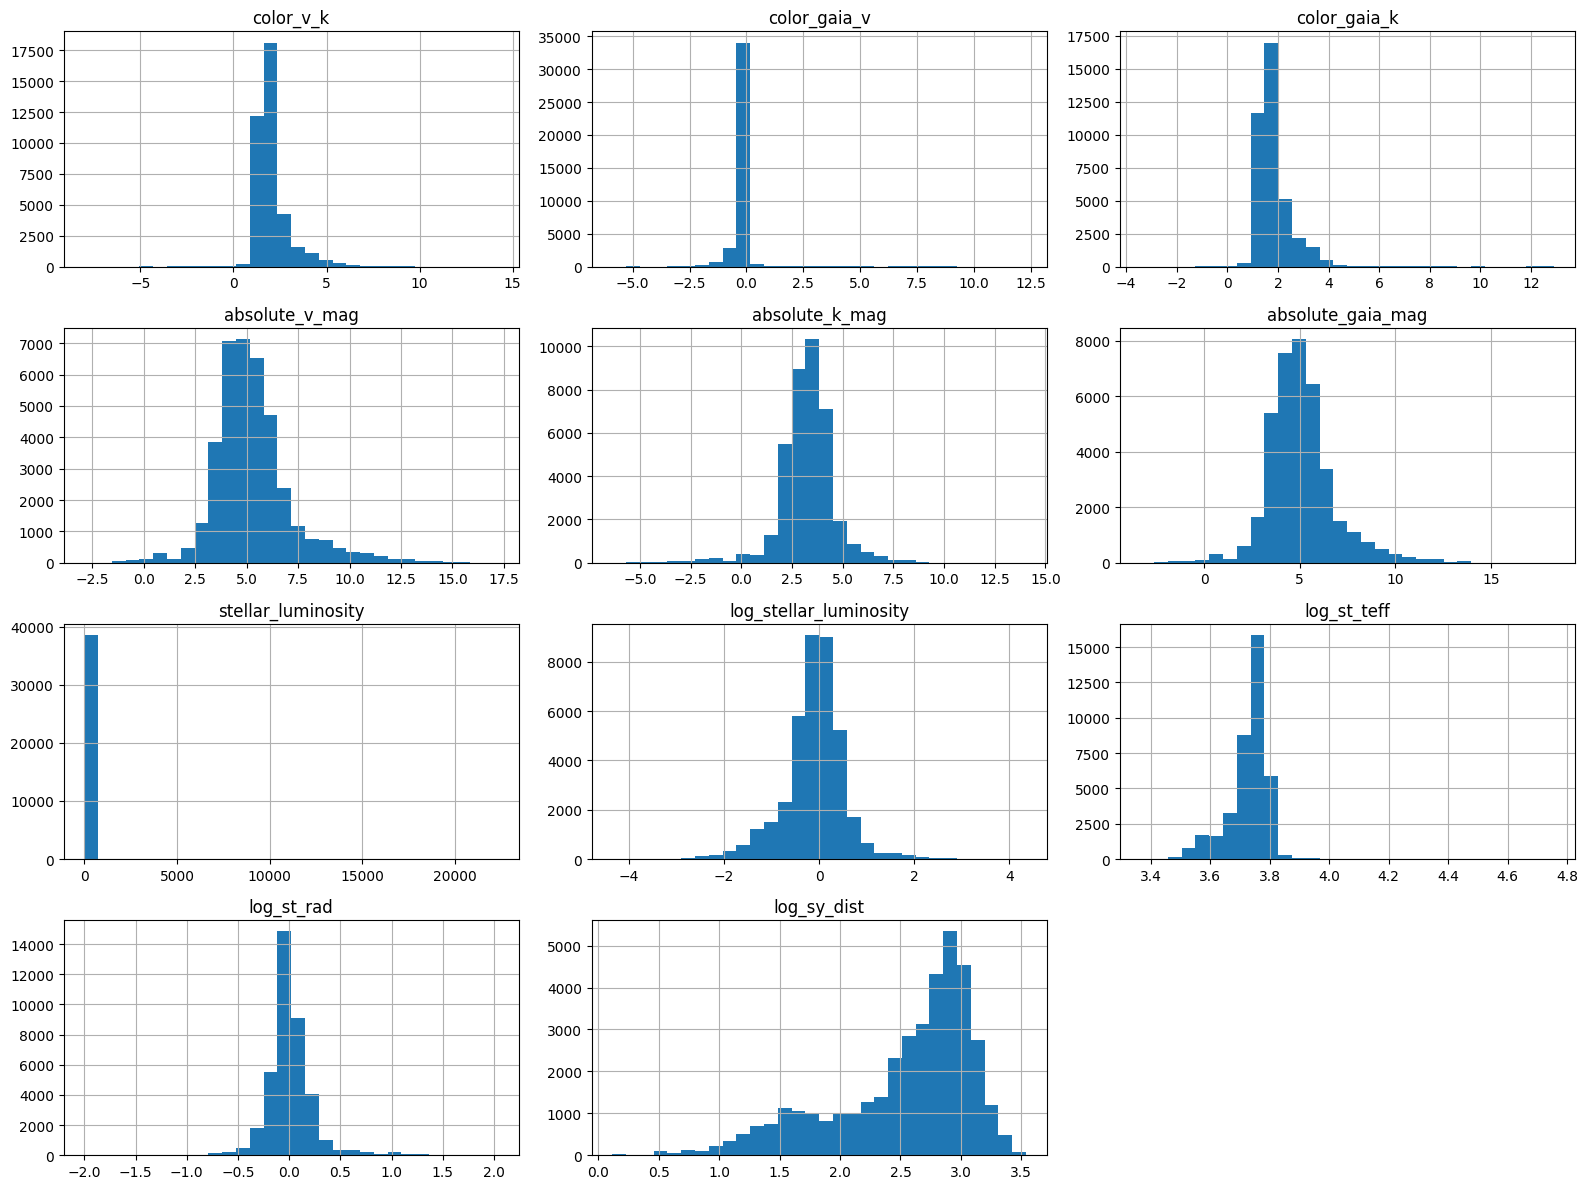

In [14]:
new_features = [
    "color_v_k",
    "color_gaia_v",
    "color_gaia_k",
    "absolute_v_mag",
    "absolute_k_mag",
    "absolute_gaia_mag",
    "stellar_luminosity",
    "log_stellar_luminosity",
    "log_st_teff",
    "log_st_rad",
    "log_sy_dist"
]

df[new_features].hist(
    figsize=(16, 12),
    bins=30
)

plt.tight_layout()
plt.show()

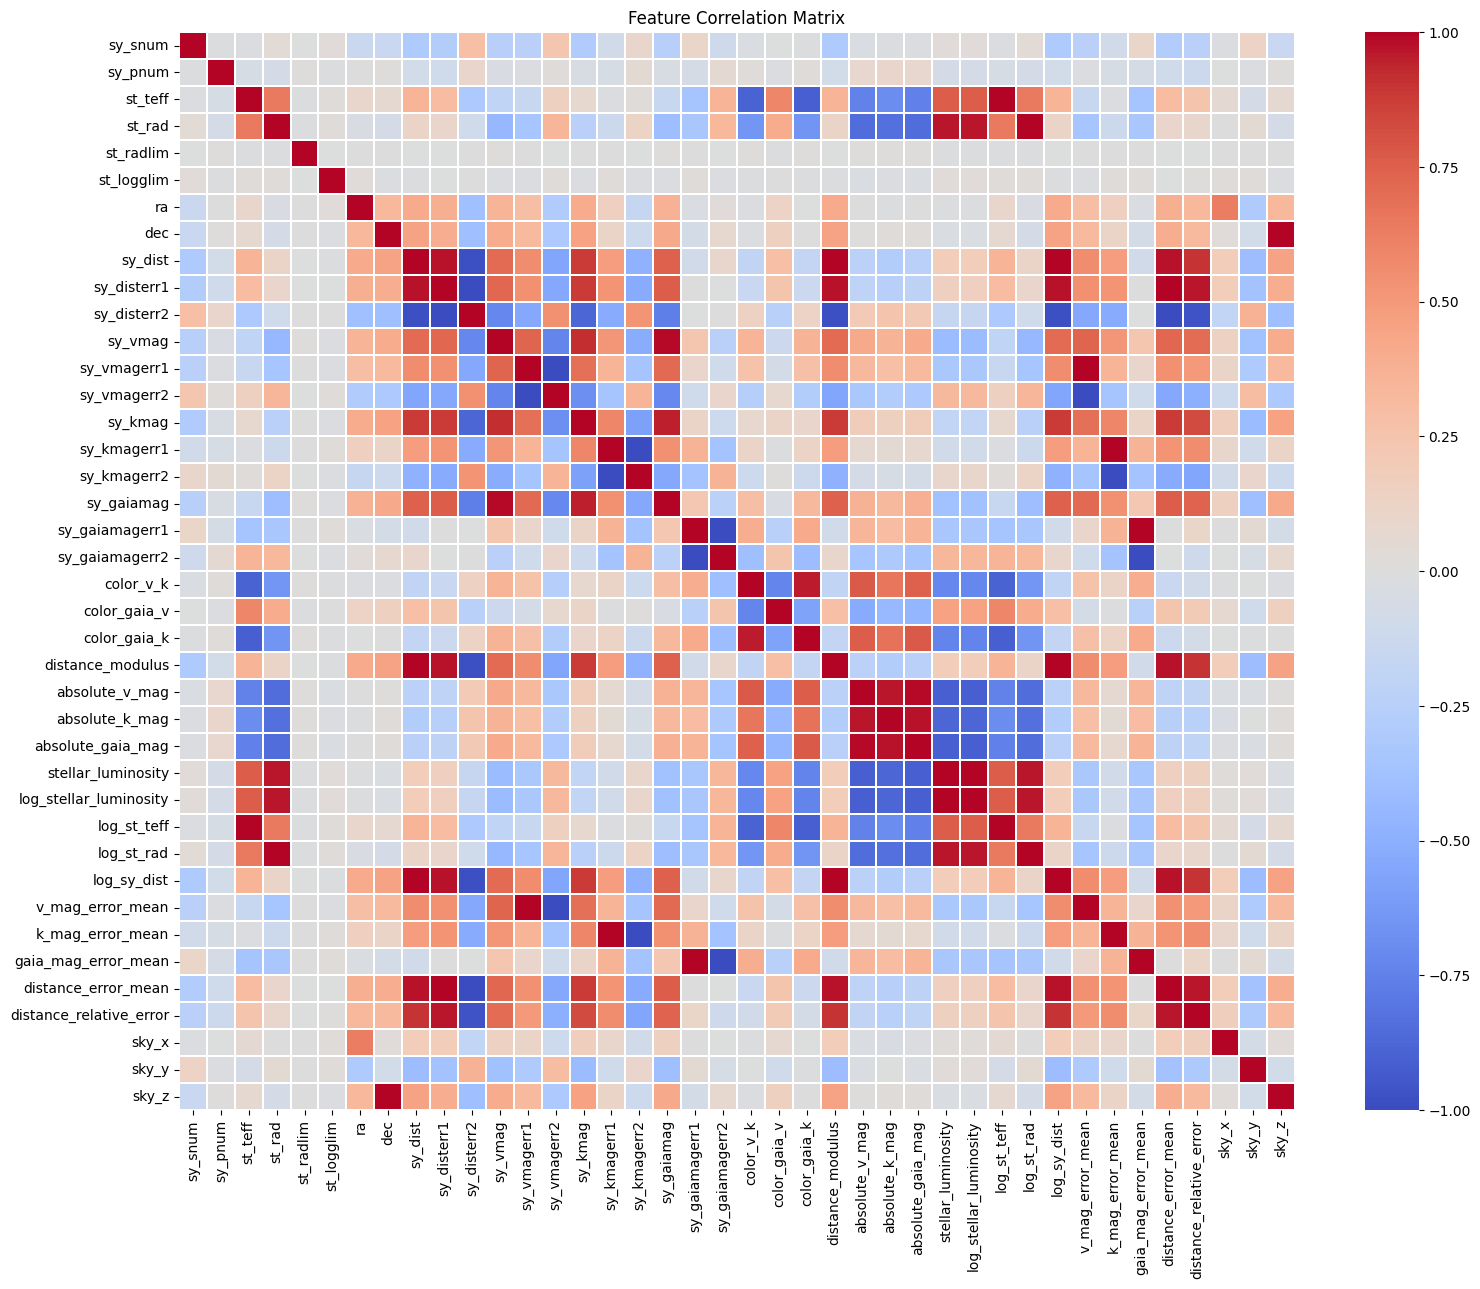

In [15]:
plt.figure(figsize=(18, 14))

correlation = df.select_dtypes(include=np.number).corr(method="spearman")

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    linewidths=0.3
)

plt.title("Feature Correlation Matrix")

plt.show()

In [16]:
corr_matrix = df.select_dtypes(include=np.number).corr(method="spearman")

upper_triangle = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

high_corr = (
    upper_triangle.stack()
    .loc[lambda x: x.abs() > 0.95]
    .sort_values(key=abs, ascending=False)
)

print(high_corr)

sy_vmagerr1             sy_vmagerr2               -1.000000
                        v_mag_error_mean           1.000000
stellar_luminosity      log_stellar_luminosity     1.000000
distance_modulus        log_sy_dist                1.000000
dec                     sky_z                      1.000000
sy_gaiamagerr2          gaia_mag_error_mean       -1.000000
sy_gaiamagerr1          gaia_mag_error_mean        1.000000
                        sy_gaiamagerr2            -1.000000
sy_kmagerr2             k_mag_error_mean          -1.000000
sy_kmagerr1             k_mag_error_mean           1.000000
                        sy_kmagerr2               -1.000000
sy_vmagerr2             v_mag_error_mean          -1.000000
st_teff                 log_st_teff                1.000000
st_rad                  log_st_rad                 1.000000
sy_dist                 distance_modulus           1.000000
                        log_sy_dist                1.000000
sy_disterr1             distance_error_m

### Define the target

In [20]:
df['sy_pnum'].value_counts()

sy_pnum
1.0    27265
2.0     6998
3.0     2665
4.0     1090
5.0      410
6.0      127
8.0       17
7.0        9
Name: count, dtype: int64

In [21]:
df = df[~df["sy_pnum"].isin([5, 6, 7, 8])]

In [22]:
print(df["sy_pnum"].value_counts().sort_index())

sy_pnum
1.0    27265
2.0     6998
3.0     2665
4.0     1090
Name: count, dtype: int64


In [23]:
print("\nNew dataset shape:", df.shape)


New dataset shape: (38018, 41)


In [24]:
import os
data_dir = os.path.abspath(os.path.join(os.getcwd(), '..', 'Data'))
output_filename = os.path.join(data_dir, 'Modeling_Data.csv')

df.to_csv(output_filename, index=False)